# Batch Digester Analysis (D1–D4)

Reads the data saved by `pull_data.py` (no PI access here), splits it into batches, calculates the H-factor per batch and compares the 4 digesters.

In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

import config
from pull_data import load_data
from batch import all_phase_tables, build_batch_table
from hfactor import h_factor_per_batch

sns.set_theme(style="whitegrid")

## 1. Load saved data

In [3]:
DATA_NAME = f"digester_{config.START_TIME[:10]}_{config.END_TIME[:10]}"
df = load_data(DATA_NAME)
print(df.shape, df.index.min(), df.index.max())
df.head()

(17569, 99) 2026-08-01 00:00:00 2026-10-01 00:00:00


,black_liquor_conductivity,D1_batch_number,D1_pfactor_setpoint,D1_pfactor_actual,D2_batch_number,D2_pfactor_setpoint,D2_pfactor_actual,D3_batch_number,D3_pfactor_setpoint,D3_pfactor_actual,...,D4_ventilation_temp,D4_displacement_liquor_temp,D4_chip_weight,D1_press1_status,D2_press1_status,D3_press1_status,D4_press1_status,press1_brightness,press1_kappa,press1_viscosity
timestamp,,,,,,,,,,,,,,,,,,,,,
2026-08-01 00:00:00,88.296875,8910,320,485.676392,8912,320,153.856216,8911,320,353.069519,...,90.0,100.197533,20.726858,0.060105,2.0,0.106690,0.0,35.000000,9.00000,816.000000
2026-08-01 00:05:00,88.296875,8910,320,485.679016,8912,320,174.696579,8911,320,353.069519,...,90.0,98.630981,30.940813,0.061873,2.0,0.102824,0.0,34.962502,9.03125,815.291687
2026-08-01 00:10:00,88.296875,8910,320,485.681671,8912,320,197.454712,8911,320,353.069519,...,90.0,97.064430,41.154766,0.063641,2.0,0.098958,0.0,34.924999,9.06250,814.583313
2026-08-01 00:15:00,88.296875,8910,320,485.684296,8912,320,222.423965,8911,320,353.069519,...,90.0,95.497879,51.368721,0.065409,2.0,0.095093,0.0,34.887501,9.09375,813.875000
2026-08-01 00:20:00,88.296875,8910,320,485.686920,8912,320,247.992493,8911,320,353.069519,...,90.0,93.931320,61.582676,0.067176,2.0,0.091227,0.0,34.849998,9.12500,813.166687


## 2. Phase table and batch table

In [4]:
phases = all_phase_tables(df)
batches = build_batch_table(phases)

print("Phases seen:", phases["phase"].unique())
print("Batches per digester:")
print(batches["digester"].value_counts().sort_index())
batches.head()

Phases seen: <StringArray>
[      'DISPLACEMENT',          'DISCHARGE',       'CHIP FILLING',
          'PREHYDRAU', 'HOT LIQUOR FILLING',          'HEAT&COOK',
               'WAIT',                  '8',                  '0']
Length: 9, dtype: str
Batches per digester:
digester
1    259
2    258
3    256
4    176
Name: count, dtype: int64


,digester,batch_id,batch_number,start,end,minutes_0,minutes_8,minutes_CHIP FILLING,minutes_DISCHARGE,minutes_DISPLACEMENT,minutes_HEAT&COOK,minutes_HOT LIQUOR FILLING,minutes_PREHYDRAU,minutes_WAIT
0,1,1,8910,2026-08-01 01:20:00,2026-08-01 07:25:00,NaN,NaN,35.0,80.0,25.0,35.0,70.0,70.0,20.0
1,1,2,8914,2026-08-01 07:30:00,2026-08-01 12:10:00,NaN,NaN,30.0,15.0,30.0,30.0,70.0,80.0,NaN
2,1,3,8917,2026-08-01 12:15:00,2026-08-01 17:10:00,NaN,NaN,30.0,10.0,30.0,35.0,65.0,100.0,NaN
3,1,4,8920,2026-08-01 17:15:00,2026-08-01 21:55:00,NaN,NaN,30.0,5.0,30.0,35.0,70.0,85.0,NaN
4,1,5,8923,2026-08-01 22:00:00,2026-08-02 03:10:00,NaN,NaN,35.0,40.0,30.0,35.0,75.0,70.0,NaN


## 3. H-factor per batch

In [5]:
hf = h_factor_per_batch(df, phases, config.H_FACTOR_PHASES)
batches = batches.merge(hf, on=["digester", "batch_id"], how="left")
batches[["digester", "batch_id", "batch_number", "start", "h_factor", "max_circulation_temp"]].head()

,digester,batch_id,batch_number,start,h_factor,max_circulation_temp
0,1,1,8910,2026-08-01 01:20:00,137.031040,156.214157
1,1,2,8914,2026-08-01 07:30:00,132.240564,155.710587
2,1,3,8917,2026-08-01 12:15:00,131.526606,155.349609
3,1,4,8920,2026-08-01 17:15:00,160.779251,161.453125
4,1,5,8923,2026-08-01 22:00:00,153.048385,157.935165


## 4. Volatility per digester (Mean, SD, CV%)

In [6]:
def volatility_table(batches, col):
    g = batches.groupby("digester")[col]
    table = pd.DataFrame({"N": g.count(), "Mean": g.mean(), "SD": g.std(),
                          "Min": g.min(), "Max": g.max()})
    table["CV%"] = 100 * table["SD"] / table["Mean"]
    return table.round(2)

for col in ["h_factor", "max_circulation_temp", "minutes_HEAT&COOK", "minutes_PREHYDRAU"]:
    if col in batches.columns:
        print(f"\n{col}")
        display(volatility_table(batches, col))


h_factor


,N,Mean,SD,Min,Max,CV%
digester,,,,,,
1,256,150.05,22.57,25.74,288.12,15.04
2,256,155.81,18.19,115.79,253.14,11.67
3,254,157.48,17.57,0.00,206.25,11.16
4,174,163.37,17.95,113.05,211.42,10.99



max_circulation_temp


,N,Mean,SD,Min,Max,CV%
digester,,,,,,
1,256,157.41,1.65,150.76,163.99,1.05
2,256,159.33,1.05,153.61,162.42,0.66
3,254,157.46,4.74,85.41,163.36,3.01
4,174,158.48,1.18,154.80,162.01,0.74



minutes_HEAT&COOK


,N,Mean,SD,Min,Max,CV%
digester,,,,,,
1,256,36.86,6.15,10.0,95.0,16.69
2,256,30.04,6.72,20.0,115.0,22.36
3,254,34.35,5.95,0.0,55.0,17.33
4,174,35.95,4.38,25.0,55.0,12.18



minutes_PREHYDRAU


,N,Mean,SD,Min,Max,CV%
digester,,,,,,
1,256,81.72,55.12,60.0,745.0,67.45
2,257,84.42,8.09,55.0,120.0,9.59
3,254,80.94,14.53,10.0,270.0,17.95
4,174,87.76,14.67,65.0,235.0,16.72


## 5. H-factor by digester (boxplot)

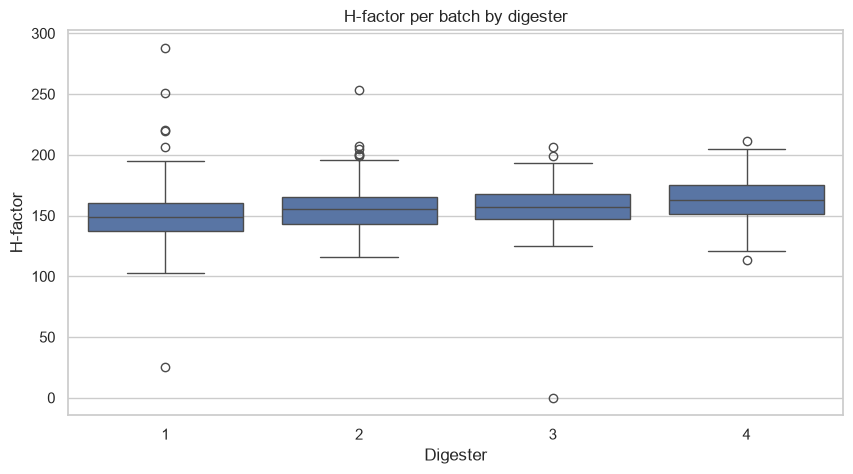

In [7]:
plt.figure(figsize=(10, 5))
sns.boxplot(data=batches, x="digester", y="h_factor")
plt.title("H-factor per batch by digester")
plt.xlabel("Digester")
plt.ylabel("H-factor")
plt.show()

## 6. H-factor trend over time

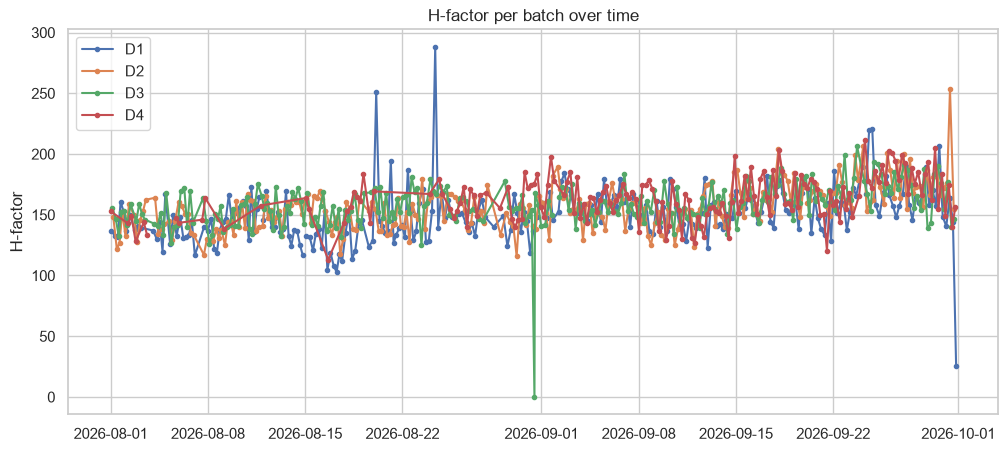

In [8]:
plt.figure(figsize=(12, 5))
for dig in [1, 2, 3, 4]:
    b = batches[batches["digester"] == dig]
    plt.plot(b["start"], b["h_factor"], marker=".", linestyle="-", label=f"D{dig}")
plt.legend()
plt.title("H-factor per batch over time")
plt.ylabel("H-factor")
plt.show()

## 7. Sensor values at real lab times (one table per lab value)

- Times every `config.LAB_INTERVAL` (e.g. 1h: 10:00, 11:00, ...).
- A time is **skipped** when the log book has no value for that lab parameter.
- Sensor values are taken at that **exact moment**.
- Lab values come from the log book (real samples), not from PI (PI interpolates them).
- Note: Press 1 lab reflects pulp cooked hours earlier. For digester cooking tags, link by batch later.

In [9]:
from lab import load_lab_samples, lab_tables

# Real lab samples from the log book (first run reads the Excel files, then uses data/lab_samples.csv)
lab = load_lab_samples(refresh=False)
print("Lab samples:", len(lab), lab.index.min(), "->", lab.index.max())

tables = lab_tables(df, lab, config.LAB_INTERVAL)
for name, table in tables.items():
    print(f"{name:20s} {len(table):5d} times kept (interval {config.LAB_INTERVAL})")

Lab samples: 2698 2026-01-01 08:00:00 -> 2026-10-14 08:00:00
press1_kappa           356 times kept (interval 1h)
press1_viscosity       354 times kept (interval 1h)
press1_brightness      683 times kept (interval 1h)


In [10]:
# Look at one table: lab value + sensor values at the same moment
kappa_table = tables["press1_kappa"]
kappa_table.head()

,press1_kappa,black_liquor_conductivity,D1_batch_number,D1_pfactor_setpoint,D1_pfactor_actual,D2_batch_number,D2_pfactor_setpoint,D2_pfactor_actual,D3_batch_number,D3_pfactor_setpoint,...,D4_digester_pressure,D4_bottom_circulation_temp,D4_circulation_temp,D4_ventilation_temp,D4_displacement_liquor_temp,D4_chip_weight,D1_press1_status,D2_press1_status,D3_press1_status,D4_press1_status
timestamp,,,,,,,,,,,,,,,,,,,,,
2026-08-01 00:00:00,9.8,88.296875,8910,320,485.676392,8912,320,153.856216,8911,320,...,-0.009551,83.385147,83.637367,90.0,100.197533,20.726858,0.060105,2.0,0.10669,0.0
2026-08-01 04:00:00,10.0,86.855469,8914,320,393.292206,8912,320,349.847595,8915,320,...,6.453933,160.352112,149.470734,90.0,158.329742,186.668274,0.000000,0.0,3.00000,0.0
2026-08-01 08:00:00,8.8,49.414062,8914,320,0.043105,8916,320,342.899689,8915,320,...,-0.021348,79.357788,80.046745,90.0,98.469772,0.553020,1.000000,0.0,0.00000,0.0
2026-08-01 12:00:00,9.7,90.773438,8917,320,372.281952,8919,320,153.500900,8918,320,...,-0.057865,73.318459,75.821838,90.0,91.788818,0.553020,0.031296,0.0,0.00000,0.0
2026-08-01 16:00:00,9.5,151.476562,8920,320,389.423706,8919,320,0.006385,8921,320,...,-0.021348,68.225075,72.413727,90.0,85.345078,1.077094,0.000000,0.0,3.00000,0.0


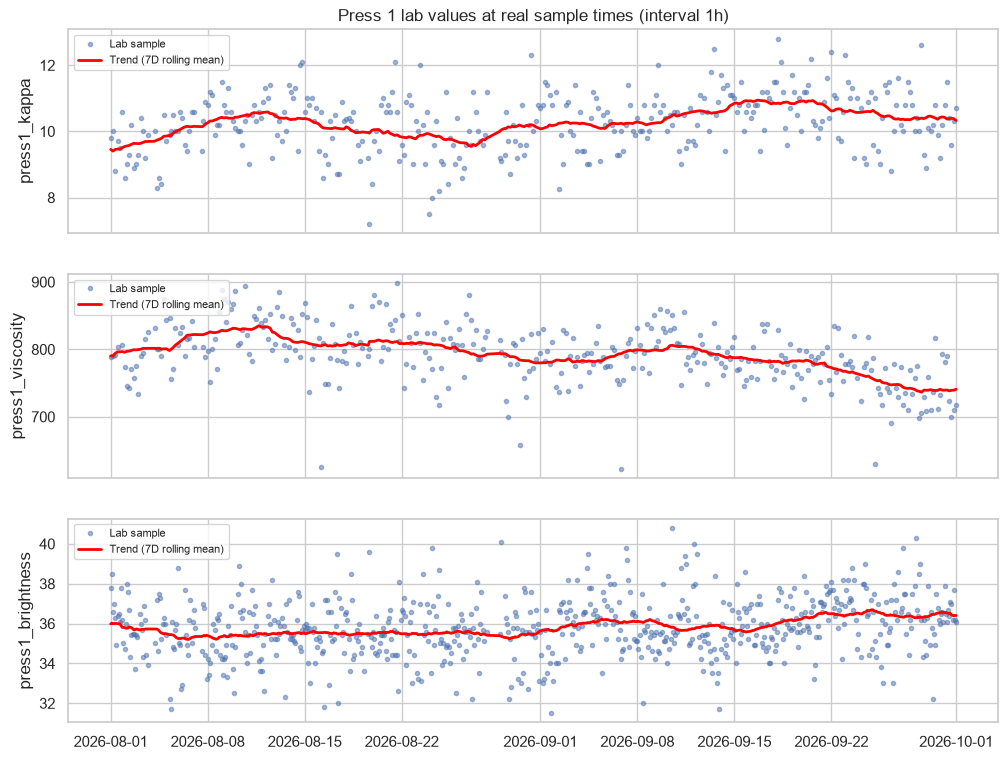

In [11]:
# Plot each lab value at its real sample times, with a rolling-mean trend line
TREND_WINDOW = "7D"   # trend = average of the samples within this window (e.g. "12h", "24h", "3D")

fig, axes = plt.subplots(3, 1, figsize=(12, 9), sharex=True)
for ax, (name, table) in zip(axes, tables.items()):
    values = table[name].dropna()
    trend = values.rolling(TREND_WINDOW, center=True, min_periods=1).mean()
    ax.plot(values.index, values, marker=".", linestyle="none", alpha=0.5, label="Lab sample")
    ax.plot(trend.index, trend, color="red", linewidth=2, label=f"Trend ({TREND_WINDOW} rolling mean)")
    ax.set_ylabel(name)
    ax.legend(fontsize=8, loc="upper left")
axes[0].set_title(f"Press 1 lab values at real sample times (interval {config.LAB_INTERVAL})")
plt.show()

## 8. Lab quality histograms by digester (D1–D4)

- Data: the lab tables from section 7 (real log book samples only).
- Digester at each lab time: `Dk_press1_status == k` exactly, and only one digester matches.
- Lines: Mean, Median, ±2σ band; green band = SOP (`config.LAB_SOP_LIMITS`, **not yet confirmed**).

In [12]:
import numpy as np
from lab import assign_digester

# Add the digester to each lab table
tables = {name: assign_digester(table) for name, table in tables.items()}
for name, table in tables.items():
    print(f"{name:20s} digester counts:", table["digester"].value_counts().sort_index().to_dict(),
          "| no digester:", table["digester"].isna().sum())


def plot_hist_by_digester(table, col, label, color, xlim=None, bin_width=None):
    """4 histograms (D1-D4) of one lab value with Mean, Median, ±2σ and SOP band."""
    fig, axes = plt.subplots(4, 1, figsize=(10, 16))
    for ax, dig in zip(axes, [1, 2, 3, 4]):
        vals = table.loc[table["digester"] == dig, col].dropna()
        if len(vals) == 0:
            ax.text(0.5, 0.5, f"No data for D{dig}", ha="center", va="center", color="gray")
            ax.set_title(f"D{dig}")
            continue

        bins = 30
        if xlim is not None and bin_width is not None:
            bins = np.arange(xlim[0], xlim[1] + bin_width, bin_width)

        mu, sd = vals.mean(), vals.std()
        ax.hist(vals, bins=bins, color=color, edgecolor="black", alpha=0.75)
        ax.axvline(mu, color="red", linestyle="--", linewidth=1.5, label=f"Mean = {mu:.2f}")
        ax.axvline(vals.median(), color="black", linestyle=":", linewidth=1.5, label=f"Median = {vals.median():.2f}")
        ax.axvspan(mu - 2 * sd, mu + 2 * sd, color="purple", alpha=0.08,
                   label=f"±2σ [{mu - 2 * sd:.2f}, {mu + 2 * sd:.2f}]")
        if col in config.LAB_SOP_LIMITS:
            sop_lo, sop_hi = config.LAB_SOP_LIMITS[col]
            ax.axvspan(sop_lo, sop_hi, color="green", alpha=0.12, label=f"SOP {sop_lo}-{sop_hi}")
        if xlim is not None:
            ax.set_xlim(xlim)
        ax.set_title(f"D{dig}  (N = {len(vals)})")
        ax.set_xlabel(label)
        ax.set_ylabel("Count (lab samples)")
        ax.legend(fontsize=8)
    fig.suptitle(f"{label} histogram by digester (real lab samples)", fontsize=15)
    plt.tight_layout()
    plt.show()


def summary_table(table, col):
    """N, Mean, Median, SD, ±2σ, SOP and % in SOP per digester (same data as the histogram)."""
    sop_lo, sop_hi = config.LAB_SOP_LIMITS.get(col, (np.nan, np.nan))
    groups = [(f"D{d}", table.loc[table["digester"] == d, col]) for d in [1, 2, 3, 4]]
    groups.append(("All", table.loc[table["digester"].notna(), col]))
    rows = []
    for name, vals in groups:
        vals = vals.dropna()
        mu, sd = vals.mean(), vals.std()
        rows.append({"Digester": name, "N": len(vals), "Mean": mu, "Median": vals.median(),
                     "SD": sd, "-2σ": mu - 2 * sd, "+2σ": mu + 2 * sd,
                     "SOP Low": sop_lo, "SOP High": sop_hi,
                     "% in SOP": vals.between(sop_lo, sop_hi).mean() * 100})
    return pd.DataFrame(rows).set_index("Digester").round(2)

press1_kappa         digester counts: {1.0: 75, 2.0: 87, 3.0: 75, 4.0: 63} | no digester: 56
press1_viscosity     digester counts: {1.0: 74, 2.0: 87, 3.0: 74, 4.0: 63} | no digester: 56
press1_brightness    digester counts: {1.0: 128, 2.0: 159, 3.0: 151, 4.0: 122} | no digester: 123


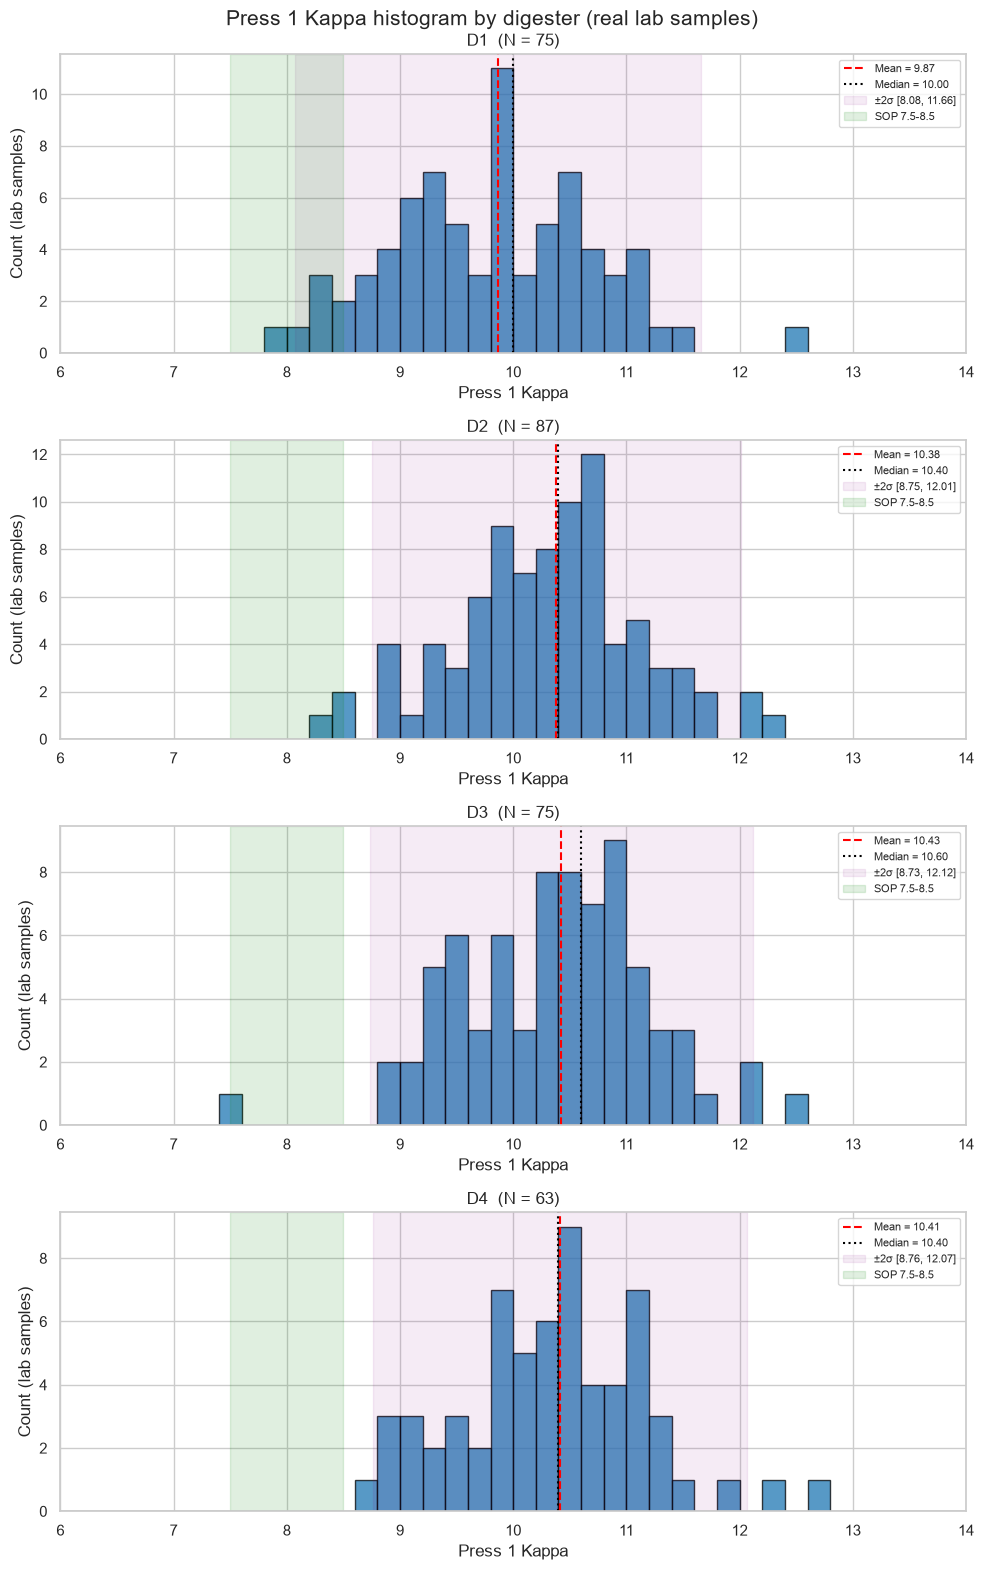

,N,Mean,Median,SD,-2σ,+2σ,SOP Low,SOP High,% in SOP
Digester,,,,,,,,,
D1,75,9.87,10.0,0.89,8.08,11.66,7.5,8.5,6.67
D2,87,10.38,10.4,0.82,8.75,12.01,7.5,8.5,1.15
D3,75,10.43,10.6,0.85,8.73,12.12,7.5,8.5,1.33
D4,63,10.41,10.4,0.83,8.76,12.07,7.5,8.5,0.00
All,300,10.27,10.3,0.87,8.52,12.02,7.5,8.5,2.33


In [21]:
# Kappa — adjust KAPPA_XLIM / KAPPA_BIN_WIDTH to zoom
KAPPA_XLIM = (6, 14)
KAPPA_BIN_WIDTH = 0.2
plot_hist_by_digester(tables["press1_kappa"], "press1_kappa", "Press 1 Kappa", "#1f77b4",
                      xlim=KAPPA_XLIM, bin_width=KAPPA_BIN_WIDTH)
display(summary_table(tables["press1_kappa"], "press1_kappa"))

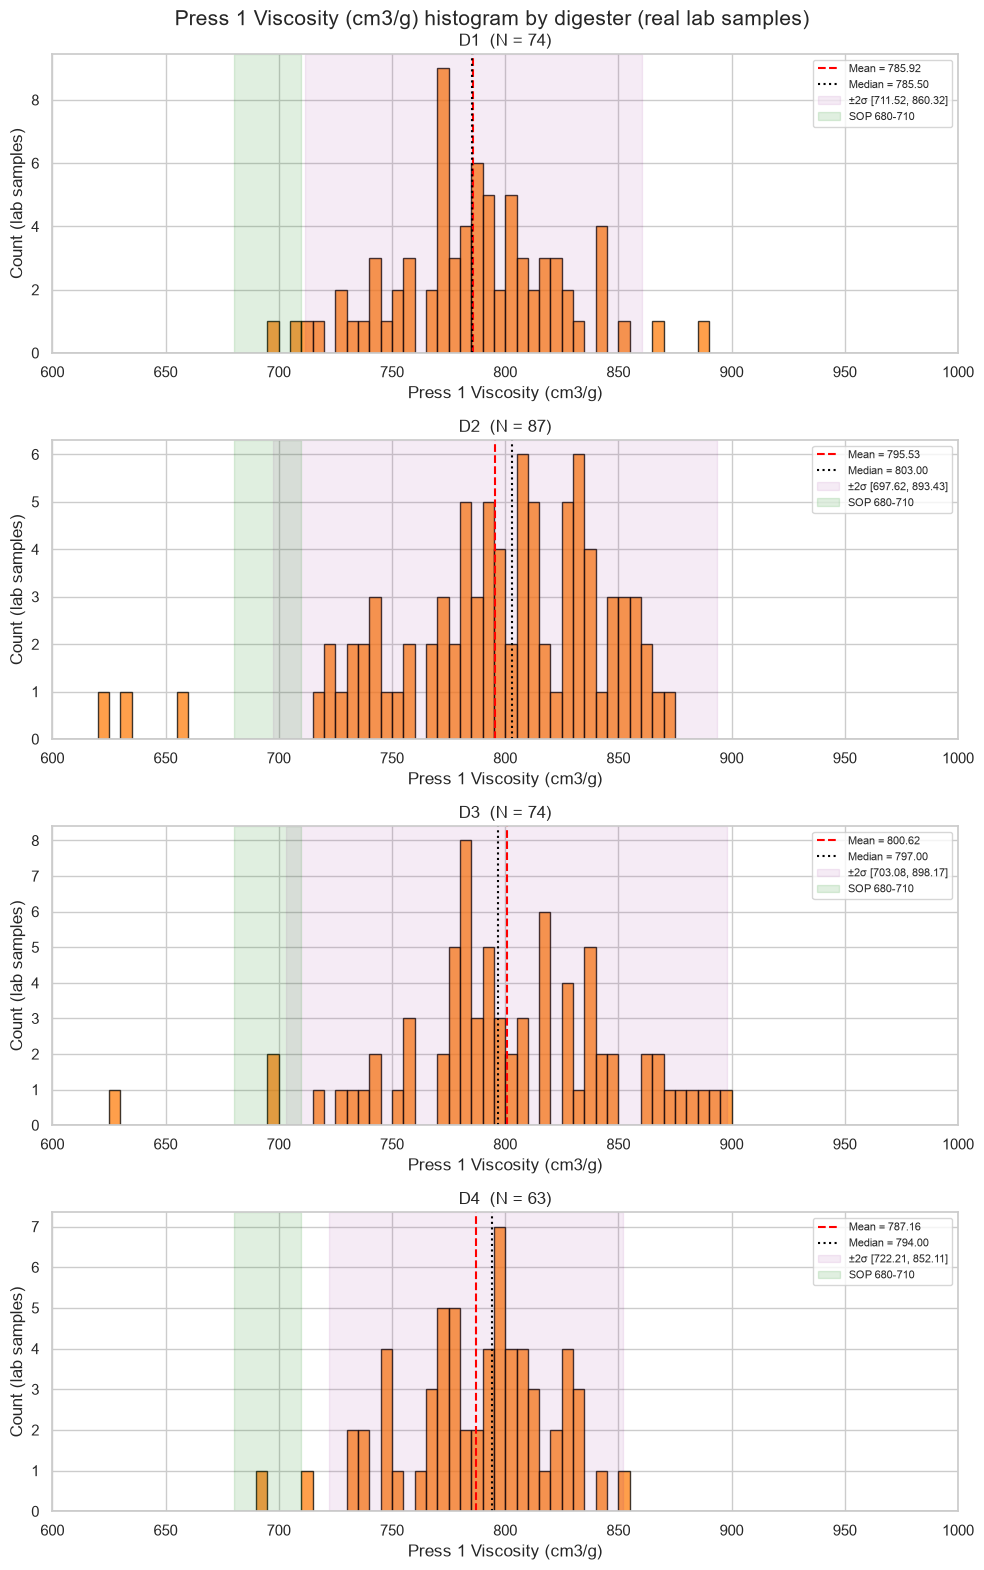

,N,Mean,Median,SD,-2σ,+2σ,SOP Low,SOP High,% in SOP
Digester,,,,,,,,,
D1,74,785.92,785.5,37.20,711.52,860.32,680,710,4.05
D2,87,795.53,803.0,48.95,697.62,893.43,680,710,0.00
D3,74,800.62,797.0,48.77,703.08,898.17,680,710,2.70
D4,63,787.16,794.0,32.48,722.21,852.11,680,710,3.17
All,298,792.64,793.5,43.30,706.04,879.24,680,710,2.35


In [19]:
# Viscosity — adjust VISC_XLIM / VISC_BIN_WIDTH to zoom
VISC_XLIM = (600, 1000)
VISC_BIN_WIDTH = 5
plot_hist_by_digester(tables["press1_viscosity"], "press1_viscosity", "Press 1 Viscosity (cm3/g)", "#ff7f0e",
                      xlim=VISC_XLIM, bin_width=VISC_BIN_WIDTH)
display(summary_table(tables["press1_viscosity"], "press1_viscosity"))

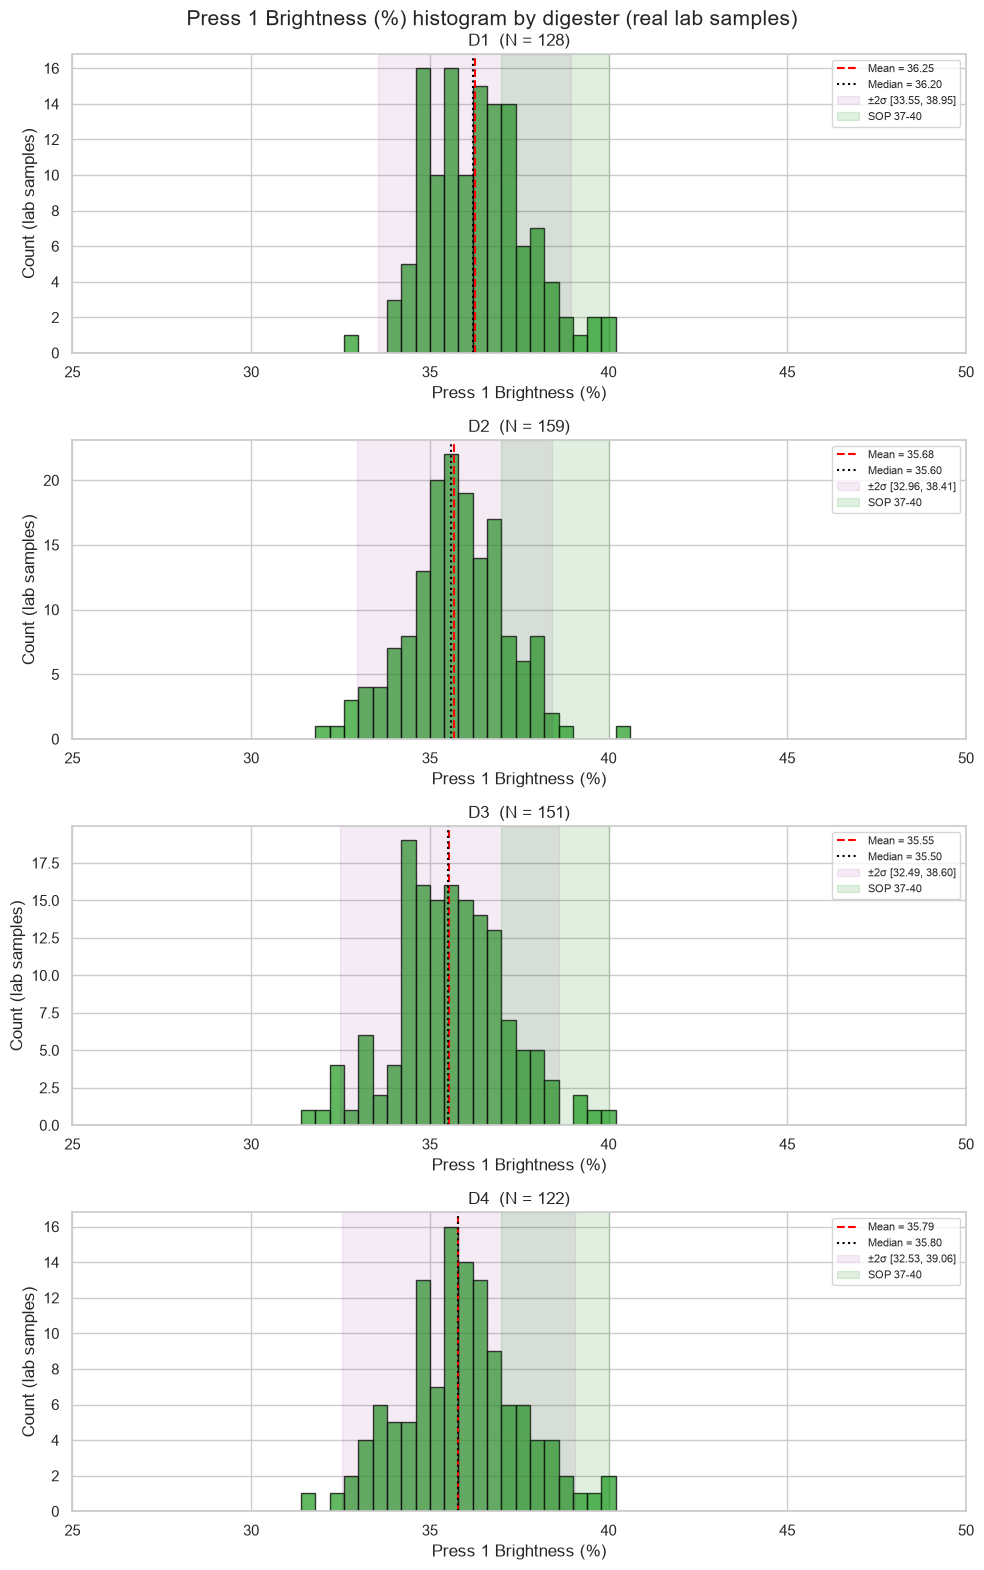

,N,Mean,Median,SD,-2σ,+2σ,SOP Low,SOP High,% in SOP
Digester,,,,,,,,,
D1,128,36.25,36.2,1.35,33.55,38.95,37,40,28.91
D2,159,35.68,35.6,1.36,32.96,38.41,37,40,15.72
D3,151,35.55,35.5,1.53,32.49,38.60,37,40,15.89
D4,122,35.79,35.8,1.63,32.53,39.06,37,40,21.31
All,560,35.80,35.8,1.49,32.83,38.77,37,40,20.00


In [20]:
# Brightness — adjust BRIGHT_XLIM / BRIGHT_BIN_WIDTH to zoom
BRIGHT_XLIM = (25, 50)
BRIGHT_BIN_WIDTH = 0.4
plot_hist_by_digester(tables["press1_brightness"], "press1_brightness", "Press 1 Brightness (%)", "#2ca02c",
                      xlim=BRIGHT_XLIM, bin_width=BRIGHT_BIN_WIDTH)
display(summary_table(tables["press1_brightness"], "press1_brightness"))

## 9. Digester-specific cross-correlation: batch cooking values vs lab quality

Each lab sample (digester k at Press 1) is linked to **digester k's most recent batch that started discharging before the sample** (at most 12 h before).
Rows = that batch's cooking values (X), columns = Press 1 Kappa / Viscosity / Brightness (Y). Pearson r, one heatmap per digester.

Caution: batches are not filtered yet (fake phases "8"/"0", H = 0 batches), so treat r values as a first look.

In [16]:
from batch import add_batch_values
from lab import link_to_batch

# Per-batch cooking values (X)
batches = add_batch_values(df, phases, batches)
BATCH_X = ["h_factor", "max_circulation_temp", "pfactor_final", "chip_weight",
           "minutes_PREHYDRAU", "minutes_HOT LIQUOR FILLING", "minutes_HEAT&COOK"]
BATCH_X = [c for c in BATCH_X if c in batches.columns]

# Link each lab table to its batch
linked = {name: link_to_batch(table, batches, BATCH_X) for name, table in tables.items()}
for name, table in linked.items():
    print(f"{name:20s} linked to a batch: {table['batch_id'].notna().sum()} of {len(table)}")
linked["press1_kappa"][["digester", "batch_id", "discharge_start", "press1_kappa"] + BATCH_X].head()

press1_kappa         linked to a batch: 297 of 300
press1_viscosity     linked to a batch: 295 of 298
press1_brightness    linked to a batch: 555 of 560


,digester,batch_id,discharge_start,press1_kappa,h_factor,max_circulation_temp,pfactor_final,chip_weight,minutes_PREHYDRAU,minutes_HOT LIQUOR FILLING,minutes_HEAT&COOK
timestamp,,,,,,,,,,,
2026-08-01 00:00:00,2,NaN,NaT,9.8,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-08-01 04:00:00,3,NaN,NaT,10.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2026-08-01 08:00:00,1,1.0,2026-08-01 06:05:00,8.8,137.031040,156.214157,303.448669,87.019356,70.0,70.0,35.0
2026-08-01 16:00:00,3,2.0,2026-08-01 13:40:00,9.5,146.634370,157.570572,300.575165,78.670227,75.0,75.0,35.0
2026-08-01 20:00:00,1,3.0,2026-08-01 17:00:00,10.6,131.526606,155.349609,310.333862,89.044655,100.0,65.0,35.0


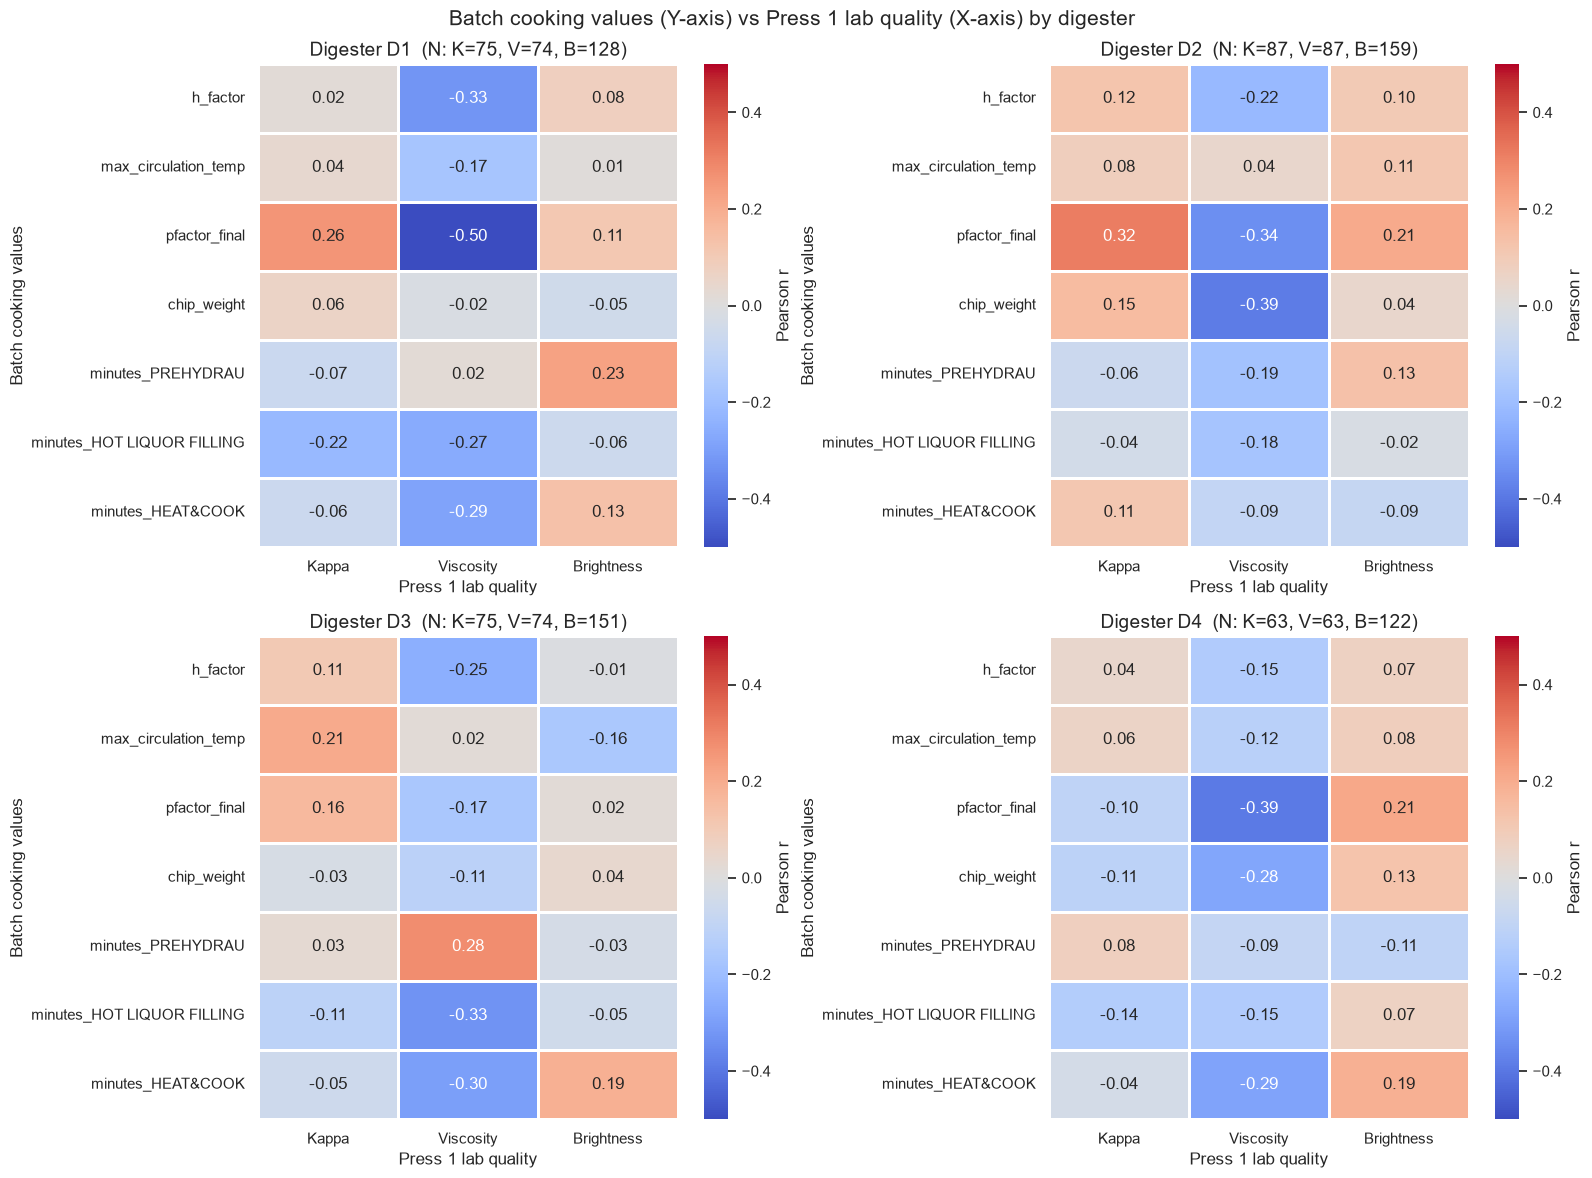

In [17]:
# Plot Digester-Specific Rectangular Cross-Correlation Matrices (Batch Cooking Values vs. Lab Quality)
LAB_LABELS = {"press1_kappa": "Kappa", "press1_viscosity": "Viscosity", "press1_brightness": "Brightness"}
CORR_LIMIT = 0.5   # color scale -0.5 .. +0.5

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    corr = pd.DataFrame(index=BATCH_X, columns=list(LAB_LABELS.values()), dtype=float)
    counts = []
    for lab_col, lab_label in LAB_LABELS.items():
        sub = linked[lab_col]
        sub = sub[sub["digester"] == dig]
        counts.append(f"{lab_label[0]}={len(sub)}")
        for x in BATCH_X:
            corr.loc[x, lab_label] = sub[x].corr(sub[lab_col])

    sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-CORR_LIMIT, vmax=CORR_LIMIT,
                linewidths=0.8, ax=ax, cbar_kws={"label": "Pearson r"})
    ax.set_title(f"Digester D{dig}  (N: {', '.join(counts)})", fontsize=14)
    ax.set_xlabel("Press 1 lab quality")
    ax.set_ylabel("Batch cooking values")

plt.suptitle("Batch cooking values (Y-axis) vs Press 1 lab quality (X-axis) by digester", fontsize=15)
plt.tight_layout()
plt.show()

## 10. Batch Master Table (1 row = 1 batch)

Everything at batch level in one table:
- **ID:** digester, batch_id, batch_number
- **Cooking rhythm:** batch_start / batch_end, and start / end of every phase (chip_filling, prehydrolysis, hot_liquor_filling, heat_and_cook, displacement, discharge, wait)
- **Cooking values (X):** minutes per phase, h_factor, max_circulation_temp, pfactor_final, chip_weight
- **Lab at Press 1 (Y):** mean of the linked samples, number of samples, time of the first sample (blank = no lab sample for this batch)

Saved to `data/batch_master.csv` so it can be opened in Excel.

In [ ]:
import os
from batch import build_batch_master
from lab import lab_per_batch

master = build_batch_master(batches, phases, lab_per_batch(linked))

path = os.path.join(config.DATA_DIR, "batch_master.csv")
master.to_csv(path, index=False)
print(f"Batch Master Table: {len(master)} batches, {master.shape[1]} columns -> saved to {path}")

# How many batches have a lab value, per digester
print("\nBatches with a lab sample:")
print(master.groupby("digester")[["press1_kappa", "press1_viscosity", "press1_brightness"]].count())

master.head()

## 11. Which H-factor gives good or bad Kappa? (per digester)

Uses the Batch Master Table (only batches that have a Kappa sample). Three views:
1. **Scatter** – each dot = 1 batch (H-factor vs Kappa) with a trend line. Dots going down to the right = more H gives lower Kappa.
2. **H-factor in 5 groups** – batches split into 5 equal-size groups by H-factor; the group with the lowest Kappa median is the "H-factor window".
3. **Good vs bad batches** – "good" = Kappa below that digester's median (change `KAPPA_GOOD` to a fixed value if needed). If good batches have clearly higher H, H is a lever.

⚠️ H-factor is still being validated (only HEAT&COOK is counted). Read the direction, not the exact number.

In [ ]:
# Batches that have both H-factor and Kappa (H-factor <= 0 = broken batch, left out)
hk = master.dropna(subset=["h_factor", "press1_kappa"])
hk = hk[hk["h_factor"] > 0].copy()
print("Batches with H-factor and Kappa:", hk.groupby("digester").size().to_dict())

# 1) Scatter H-factor vs Kappa, one chart per digester, with a straight trend line
fig, axes = plt.subplots(2, 2, figsize=(14, 10), sharex=True, sharey=True)
for ax, dig in zip(axes.flatten(), [1, 2, 3, 4]):
    d = hk[hk["digester"] == dig]
    ax.scatter(d["h_factor"], d["press1_kappa"], alpha=0.6)
    if len(d) >= 5:
        slope, intercept = np.polyfit(d["h_factor"], d["press1_kappa"], 1)
        x = np.linspace(d["h_factor"].min(), d["h_factor"].max(), 50)
        r = d["h_factor"].corr(d["press1_kappa"])
        ax.plot(x, slope * x + intercept, color="red",
                label=f"Trend: {slope * 10:+.2f} Kappa per +10 H  (r = {r:.2f})")
        ax.legend(fontsize=9)
    ax.set_title(f"D{dig}  (N = {len(d)} batches)")
    ax.set_xlabel("H-factor")
    ax.set_ylabel("Press 1 Kappa")
plt.suptitle("H-factor vs Press 1 Kappa per batch", fontsize=15)
plt.tight_layout()
plt.show()

In [ ]:
# 2) H-factor in 5 equal-size groups per digester -> Kappa in each group
H_GROUPS = 5

rows = []
for dig in [1, 2, 3, 4]:
    d = hk[hk["digester"] == dig].copy()
    if len(d) < H_GROUPS * 3:
        continue
    d["h_group"] = pd.qcut(d["h_factor"], H_GROUPS, duplicates="drop")
    for group, g in d.groupby("h_group", observed=True):
        rows.append({"Digester": f"D{dig}",
                     "H-factor range": f"{group.left:.0f} - {group.right:.0f}",
                     "Batches": len(g),
                     "Kappa median": g["press1_kappa"].median(),
                     "Kappa mean": g["press1_kappa"].mean(),
                     "Kappa SD": g["press1_kappa"].std()})
h_window = pd.DataFrame(rows).round(2)

# Mark the group with the lowest Kappa median in each digester
best = h_window.groupby("Digester")["Kappa median"].transform("min") == h_window["Kappa median"]
h_window["Lowest Kappa"] = np.where(best, "<-- best", "")
display(h_window)

In [ ]:
# 3) Good vs bad batches: compare their H-factor
KAPPA_GOOD = "median"   # "median" = below this digester's median Kappa is good; or a number, e.g. 9.5

if KAPPA_GOOD == "median":
    limit = hk.groupby("digester")["press1_kappa"].transform("median")
else:
    limit = KAPPA_GOOD
hk["kappa_class"] = np.where(hk["press1_kappa"] <= limit, "Good (low Kappa)", "Bad (high Kappa)")

plt.figure(figsize=(12, 5))
sns.boxplot(data=hk, x="digester", y="h_factor", hue="kappa_class",
            hue_order=["Bad (high Kappa)", "Good (low Kappa)"], palette=["#d62728", "#2ca02c"])
plt.title(f"H-factor of good vs bad batches (good = Kappa <= {KAPPA_GOOD})")
plt.xlabel("Digester")
plt.ylabel("H-factor")
plt.show()

summary = hk.groupby(["digester", "kappa_class"])["h_factor"].agg(["count", "median", "mean"]).round(1)
display(summary)